# Baly et al. 2020 classifiers — evaluation on `stories_10k.jsonl`

Three BERT ideology classifiers from our replication of Baly et al. 2020 (`baly/`), each trained on
the Article-Bias-Prediction corpus with the paper's settings (bert-base, 512 tokens, lr 2e-5):

| Model | Trained on | Baly test macro-F1 (ours / paper) |
|---|---|---|
| `bert_random` | random split — test outlets also seen in training | 82.20 / 80.19 |
| `bert_media` | media split — test outlets unseen | 37.13 / 35.53 |
| `bert_aa_media` | media split + adversarial outlet removal (λ = 0.7) | 33.68 / 43.87 |

Evaluated on the 30,000 **labelled source articles** in `stories_10k` (10,000 each from
left / centre / right outlets). The 10,000 LLM `neutral` summaries have no label, so they get
probabilities only.

**Two checks before trusting the numbers:**
- *Article contamination* is negligible: 71 of 30,000 titles (0.2%) also occur in Baly's corpus.
- *Outlet overlap* is not. 10 of the 11 publishers here are in Baly's corpus. Which ones each model
  trained on is worked out in section 5, where accuracy is split by seen vs unseen outlets.

In [1]:
import json, sys, math
import numpy as np, pandas as pd, torch
from pathlib import Path
from transformers import BertTokenizerFast
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

ROOT = Path("/root/ANLP/ANLP-Project")
sys.path.insert(0, str(ROOT / "baly"))
from baly import build

DATA    = ROOT / "data/stories_10k.jsonl"
MODELS  = ["bert_random", "bert_media", "bert_aa_media"]
CLASSES = ["Left", "Centre", "Right"]
SLOT2ID = {"left": 0, "center": 1, "right": 2}
BATCH, MAX_LEN = 16, 512          # Baly's input length

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tok = BertTokenizerFast.from_pretrained("bert-base-uncased")
print(device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Data

In [2]:
stories = [json.loads(l) for l in DATA.open(encoding="utf-8") if l.strip()]
src = pd.DataFrame([
    {"story_id": s["story_id"], "slot": slot, "label": SLOT2ID[slot],
     "publisher": s[slot]["publisher"], "text": s[slot]["body"]}
    for s in stories for slot in ("left", "center", "right")])
summ = pd.DataFrame([{"story_id": s["story_id"], "text": s["neutral"]} for s in stories])
print(f"labelled source articles: {len(src)}   unlabelled neutral summaries: {len(summ)}")
src.groupby(["slot", "publisher"]).size().rename("articles").to_frame()

labelled source articles: 30000   unlabelled neutral summaries: 10000


articles
slot   publisher          
center ap             1910
       hill           6089
       usatoday       2001
left   cnn             863
       dailykos       2257
       hpo            2827
       nyt            2854
       wpo            1199
right  breitbart      4644
       fox            2542
       wat            2814

## 2. Score with each model

In [3]:
@torch.no_grad()
def score(model, texts):
    out = []
    for i in range(0, len(texts), BATCH):
        e = tok(texts[i:i+BATCH], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        with torch.autocast("cuda", enabled=device.type == "cuda"):
            logits = model(e["input_ids"].to(device), e["attention_mask"].to(device))
        out.append(torch.softmax(logits.float(), 1).cpu())
    return torch.cat(out).numpy()

P_src, P_summ = {}, {}
for name in MODELS:
    m = build(3)
    m.load_state_dict(torch.load(ROOT / f"models/baly/{name}.pt", map_location="cpu", weights_only=True),
                      strict=False)          # AA checkpoint also holds its outlet head, unused here
    m.eval().to(device)
    P_src[name]  = score(m, src.text.tolist())
    P_summ[name] = score(m, summ.text.tolist())
    print(f"{name}: scored {len(src)} articles + {len(summ)} summaries", flush=True)
    del m; torch.cuda.empty_cache()

out = ROOT / "evaluation/scores"
for name in MODELS:
    d = src.drop(columns="text").copy(); d[["p_left", "p_centre", "p_right"]] = P_src[name]
    d["pred_id"] = P_src[name].argmax(1); d.to_csv(out / f"baly_{name}_source_scores.csv", index=False)
    s = summ.drop(columns="text").copy(); s[["p_left", "p_centre", "p_right"]] = P_summ[name]
    s["pred_id"] = P_summ[name].argmax(1); s.to_csv(out / f"baly_{name}_summary_scores.csv", index=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


bert_random: scored 30000 articles + 10000 summaries


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


bert_media: scored 30000 articles + 10000 summaries


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


bert_aa_media: scored 30000 articles + 10000 summaries


## 3. Confusion matrices — 30,000 labelled source articles

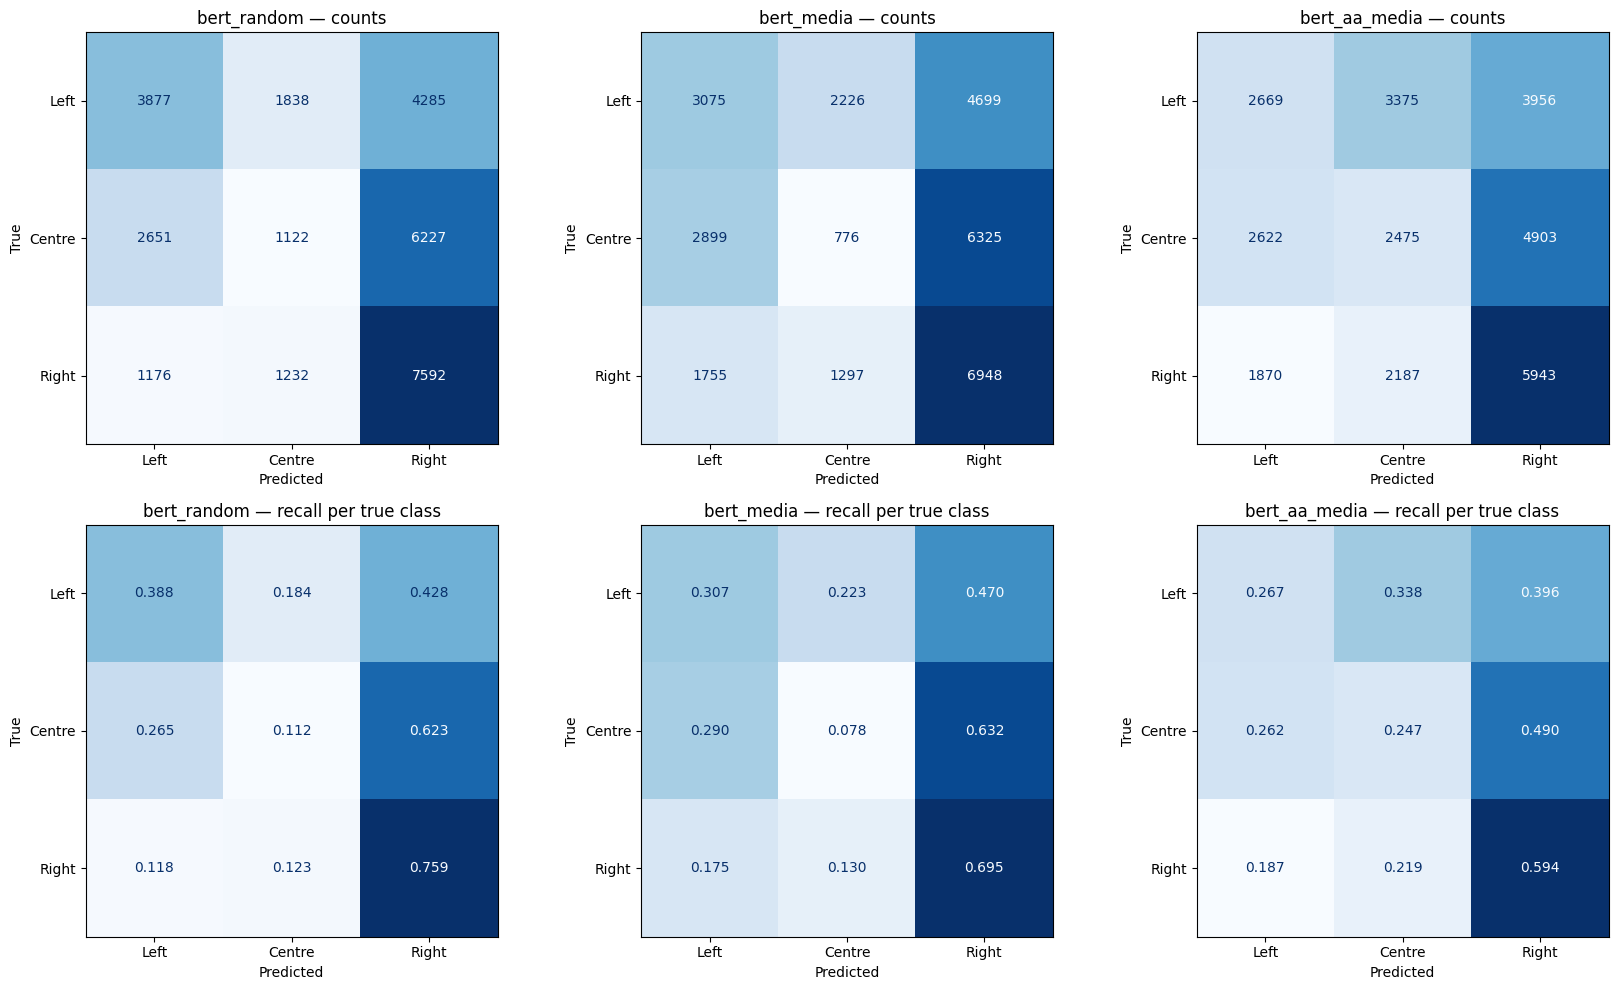

In [4]:
y = src.label.values
fig, ax = plt.subplots(2, 3, figsize=(17, 10))
for j, name in enumerate(MODELS):
    pred = P_src[name].argmax(1)
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1, 2]), display_labels=CLASSES).plot(
        ax=ax[0, j], cmap="Blues", colorbar=False, values_format="d")
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1, 2], normalize="true"), display_labels=CLASSES).plot(
        ax=ax[1, j], cmap="Blues", colorbar=False, values_format=".3f")
    ax[0, j].set_title(f"{name} — counts"); ax[1, j].set_title(f"{name} — recall per true class")
for a in ax.flat: a.set(xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.show()

In [5]:
for name in MODELS:
    pred = P_src[name].argmax(1)
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=[0, 1, 2]),
                      index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
    print(f"\n=== {name} ===\n{cm.to_string()}")
    print(classification_report(y, pred, target_names=CLASSES, digits=4))


=== bert_random ===
             pred Left  pred Centre  pred Right
true Left         3877         1838        4285
true Centre       2651         1122        6227
true Right        1176         1232        7592
              precision    recall  f1-score   support

        Left     0.5032    0.3877    0.4380     10000
      Centre     0.2677    0.1122    0.1581     10000
       Right     0.4194    0.7592    0.5403     10000

    accuracy                         0.4197     30000
   macro avg     0.3968    0.4197    0.3788     30000
weighted avg     0.3968    0.4197    0.3788     30000


=== bert_media ===
             pred Left  pred Centre  pred Right
true Left         3075         2226        4699
true Centre       2899          776        6325
true Right        1755         1297        6948
              precision    recall  f1-score   support

        Left     0.3979    0.3075    0.3469     10000
      Centre     0.1805    0.0776    0.1085     10000
       Right     0.3866    0.69

## 4. Summary metrics (Baly's metrics: macro-F1, accuracy, MAE; plus AUC)

In [6]:
def summarize(P):
    pred = P.argmax(1)
    return {"macro_F1": 100 * f1_score(y, pred, average="macro"), "accuracy": 100 * (y == pred).mean(),
            "MAE": np.abs(y - pred).mean(), "macro_AUC": roc_auc_score(y, P, multi_class="ovr", average="macro"),
            **{f"recall_{c}": (pred[y == i] == i).mean() for i, c in enumerate(CLASSES)},
            "share_pred_Right": (pred == 2).mean()}

rows = {f"Baly {n}": summarize(P_src[n]) for n in MODELS}
for label, f in [("ChunkyBERT (5 ep)", "source_article_scores.csv"),
                 ("No Classifier variant (1 ep)", "best_variant_source_scores.csv")]:
    prev = pd.read_csv(ROOT / "evaluation/scores" / f)
    key = prev.story_id.astype(str) + ":" + prev.slot          # align rows to this notebook's order
    prev = prev.set_index(key).loc[src.story_id.astype(str) + ":" + src.slot]
    rows[label] = summarize(prev[["p_left", "p_centre", "p_right"]].values)
pd.DataFrame(rows).T.round(3)

,macro_F1,accuracy,MAE,macro_AUC,recall_Left,recall_Centre,recall_Right,share_pred_Right
Baly bert_random,37.879,41.970,0.762,0.641,0.388,0.112,0.759,0.603
Baly bert_media,31.740,35.997,0.855,0.574,0.308,0.078,0.695,0.599
Baly bert_aa_media,35.491,36.957,0.825,0.560,0.267,0.248,0.594,0.493
ChunkyBERT (5 ep),40.651,44.297,0.747,0.658,0.487,0.132,0.710,0.546
No Classifier variant (1 ep),33.746,40.400,0.813,0.613,0.335,0.046,0.831,0.703


## 5. Seen vs unseen outlets

Which of the 11 publishers each model **trained on**, from Baly's split files. Outlet = web domain,
the unit Baly's media split is built on. HuffPost (`hpo`) is not in Baly's corpus at all.

This is the test Baly's paper is about. `bert_media` was designed never to be judged on an outlet
it trained on, but on this data seven of the eleven publishers were in its training set.

In [7]:
PUB2DOMAIN = {"hill": "www.thehill.com", "breitbart": "www.breitbart.com", "nyt": "www.nytimes.com",
              "hpo": None, "wat": "www.washingtontimes.com", "fox": "www.foxnews.com",
              "dailykos": "www.dailykos.com", "usatoday": "www.usatoday.com", "ap": "www.apnews.com",
              "wpo": "www.washingtonpost.com", "cnn": "www.cnn.com"}
arts = pd.read_csv(ROOT / "data/baly_articles.csv", usecols=["ID", "source_url"])
S = ROOT / "external/Article-Bias-Prediction/data/splits"
train_domains = {s: set(arts[arts.ID.isin(pd.read_csv(S / s / "train.tsv", sep="\t").ID)].source_url)
                 for s in ("media", "random")}
seen = {"bert_random": train_domains["random"], "bert_media": train_domains["media"],
        "bert_aa_media": train_domains["media"]}

tab = []
for name in MODELS:
    pred = P_src[name].argmax(1)
    s_flag = src.publisher.map(lambda p: PUB2DOMAIN[p] in seen[name] if PUB2DOMAIN[p] else False).values
    for flag, lab in [(True, "seen in training"), (False, "unseen")]:
        m = s_flag == flag
        tab.append({"model": name, "outlets": lab, "publishers": sorted(src.publisher[m].unique()),
                    "articles": int(m.sum()), "accuracy": 100 * (pred[m] == y[m]).mean(),
                    "macro_F1": 100 * f1_score(y[m], pred[m], average="macro")})
pd.DataFrame(tab).round(2)

,model,outlets,publishers,articles,accuracy,macro_F1
0,bert_random,seen in training,"[ap, breitbart, cnn, dailykos, fox, hill, nyt,...",27173,43.59,39.39
1,bert_random,unseen,[hpo],2827,26.35,13.90
2,bert_media,seen in training,"[cnn, dailykos, fox, hill, usatoday, wat, wpo]",17765,36.49,34.15
3,bert_media,unseen,"[ap, breitbart, hpo, nyt]",12235,35.28,27.47
4,bert_aa_media,seen in training,"[cnn, dailykos, fox, hill, usatoday, wat, wpo]",17765,39.43,38.76
5,bert_aa_media,unseen,"[ap, breitbart, hpo, nyt]",12235,33.36,29.56


In [8]:
acc = pd.DataFrame({n: src.assign(ok=P_src[n].argmax(1) == y).groupby(["slot", "publisher"]).ok.mean() * 100
                    for n in MODELS}).round(1)
acc["articles"] = src.groupby(["slot", "publisher"]).size()
acc["in media-split train"] = [PUB2DOMAIN[p] in train_domains["media"] if PUB2DOMAIN[p] else False
                               for _, p in acc.index]
acc["in random-split train"] = [PUB2DOMAIN[p] in train_domains["random"] if PUB2DOMAIN[p] else False
                                for _, p in acc.index]
acc

bert_random  bert_media  bert_aa_media  articles  \
slot   publisher                                                     
center ap                 4.7         2.2           19.2      1910   
       hill               8.5         5.3           17.2      6089   
       usatoday          25.6        20.6           53.1      2001   
left   cnn               78.1        82.0           79.3       863   
       dailykos          41.4        33.1           26.6      2257   
       hpo               26.4        37.7           32.6      2827   
       nyt               42.5         7.4            6.5      2854   
       wpo               26.0        28.6           23.1      1199   
right  breitbart         81.8        64.5           56.2      4644   
       fox               59.5        55.7           39.1      2542   
       wat               81.1        90.0           83.2      2814   

                  in media-split train  in random-split train  
slot   publisher                                               
center ap                        False                   True  
       hill                       True                   True  
       usatoday                   True                   True  
left   cnn                        True                   True  
       dailykos                   True                   True  
       hpo                       False                  False  
       nyt                       False                   True  
       wpo                        True                   True  
right  breitbart                 False                   True  
       fox                        True                   True  
       wat                        True                   True

## 6. Neutral summaries (unlabelled — no confusion matrix possible)

In [9]:
pd.DataFrame({n: {**{f"mean_p_{c}": P_summ[n][:, i].mean() for i, c in enumerate(CLASSES)},
                  **{f"pred_{c}": (P_summ[n].argmax(1) == i).mean() for i, c in enumerate(CLASSES)}}
              for n in MODELS}).T.round(3)

,mean_p_Left,mean_p_Centre,mean_p_Right,pred_Left,pred_Centre,pred_Right
bert_random,0.102,0.172,0.727,0.072,0.052,0.876
bert_media,0.238,0.110,0.652,0.223,0.025,0.752
bert_aa_media,0.271,0.298,0.431,0.249,0.209,0.543


## Notes

- Labels are **outlet-level**, inherited from the publisher slot, not annotated per article.
- `stories_10k` bodies are short (~870 characters, ~200 tokens), well under the 512-token window, so
  truncation does not come into play for the labelled articles.
- Per-article probabilities for every model: `evaluation/scores/baly_<model>_{source,summary}_scores.csv`.